## Assignment 1

In [43]:
%pip install numpy matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [44]:
import numpy as np
import matplotlib.pyplot as plt

In [45]:
tsn = "200101723"
d = int(tsn[-2:])
s = int(tsn[-3])

x_start = (-1)**s * (0.5 + d / 200)
print(f"x_start = {x_start}")

x_start = -0.615


In [46]:
m = 1.0
omega = 1.0
hbar = 1.0
alpha = 2.0

T_0 = 2.0 * np.pi
NT = 128
ND = 600
x = np.linspace(-4.0, 4.0, ND + 1)
t = np.linspace(0, T_0, NT + 1)
dx = x[1] - x[0]
dt = T_0 / NT

In [47]:
psi0 = (
    (alpha / np.pi) ** 0.25 * np.exp(-0.5 * alpha * (x - x_start)**2)
    ).astype(complex)

### Problem A:

In [48]:
x_b = x[:, None]
x_a = x[None, :]

sinwt = np.sin(omega * dt)
coswt = np.cos(omega * dt)
K_eps = (
    np.sqrt(m * omega / (2.0 * np.pi * 1j * hbar * sinwt)) * 
    np.exp(1j * m * omega / (2.0 * hbar * sinwt) *
           ((x_a**2 + x_b**2) * coswt - 2.0 * x_a * x_b))
)

U = dx * K_eps
K_8eps = np.linalg.matrix_power(U, 8) / dx

print(f"K_8eps shape: {K_8eps.shape}")
print("\nTruncated matrix:")
print(K_8eps)

K_8eps shape: (601, 601)

Truncated matrix:
[[-0.05955846+0.0178667j  -0.0757611 +0.0217024j  -0.07967385+0.05414053j
  ... -0.46505982-0.30932634j -0.35439299-0.42735575j
  -0.21687407-0.50917202j]
 [-0.0757611 +0.0217024j  -0.0896081 +0.03330227j -0.08308486+0.06724787j
  ... -0.53404108-0.16837676j -0.46141968-0.31131639j
  -0.35439299-0.42735575j]
 [-0.07967385+0.05414053j -0.08308486+0.06724787j -0.06226964+0.09303051j
  ... -0.56407376-0.01040964j -0.53404108-0.16837676j
  -0.46505982-0.30932634j]
 ...
 [-0.46505982-0.30932634j -0.53404108-0.16837676j -0.56407376-0.01040964j
  ... -0.06226964+0.09303051j -0.08308486+0.06724787j
  -0.07967385+0.05414053j]
 [-0.35439299-0.42735575j -0.46141968-0.31131639j -0.53404108-0.16837676j
  ... -0.08308486+0.06724787j -0.0896081 +0.03330227j
  -0.0757611 +0.0217024j ]
 [-0.21687407-0.50917202j -0.35439299-0.42735575j -0.46505982-0.30932634j
  ... -0.07967385+0.05414053j -0.0757611 +0.0217024j
  -0.05955846+0.0178667j ]]


### Problem B:

In [49]:
states = np.empty((NT + 1, ND + 1), dtype=complex)
states[0] = psi0

for n in range(NT):
    states[n + 1] = U @ states[n]

time_arr = np.linspace(0, T_0, NT + 1)
P = np.abs(states)**2
norm = dx * np.sum(P, axis=1)
x_mean = dx * np.sum(P * x_a, axis=1)
print(f"States: {states.shape}, Mean positions: {x_mean.shape}")

States: (129, 601), Mean positions: (129,)


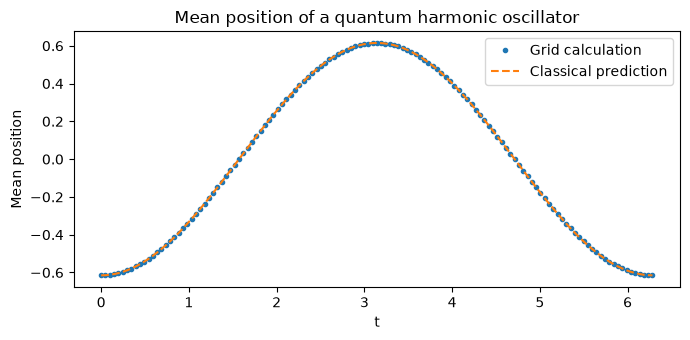

In [50]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(time_arr, x_mean, "o", markersize=3, label="Grid calculation")
ax.plot(time_arr, x_start * np.cos(omega * time_arr), "--", label="Classical prediction")
ax.set(xlabel="t", ylabel="Mean position", title="Mean position of a quantum harmonic oscillator")
ax.legend()
fig.tight_layout()
plt.show()

### Problem C: